# EJERCICIO 4: Optimización multiobjetivo de eficiencia y contaminación

Enunciado
Una ciudad busca balancear la eficiencia energética con la minimización de emisiones. Cada política aplicada en distintos barrios tiene un impacto distinto en ambos objetivos.

Debes encontrar las combinaciones más equilibradas para cada barrio.

Variables
* Genotipo: vector de políticas aplicadas por barrio
* Fitness multiobjetivo: [eficiencia, emisiones]
* Uso de NSGA-II o SPEA2

Evaluaciones
* Frontera de Pareto (eficiencia vs emisiones)
* Diversidad de soluciones no dominadas

In [1]:
%pip install deap

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Solución utilizando librería DEAP
import numpy as np
import random
import matplotlib.pyplot as plt
from deap import base, creator, tools, algorithms

In [3]:
# Variables del problema
NUM_BARRIOS = 10
NUM_POLITICAS = 4

In [4]:
# Supuestos de eficiencia y emisiones por política (valores aleatorios)
eficiencia_por_politica = np.array([70, 80, 90, 100])
emisiones_por_politica = np.array([300, 250, 200, 150])

In [5]:
# Configuración DEAP multiobjetivo
creator.create("FitnessMulti", base.Fitness, weights=(1.0, -1.0))  # Max eficiencia, Min emisiones
creator.create("IndividualMulti", list, fitness=creator.FitnessMulti)

toolbox = base.Toolbox()
toolbox.register("attr_pol", random.randint, 0, NUM_POLITICAS-1)
toolbox.register("individual", tools.initRepeat, creator.IndividualMulti, toolbox.attr_pol, n=NUM_BARRIOS)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

def eval_multi(ind):
    eficiencia_total = sum([eficiencia_por_politica[pol] for pol in ind])
    emisiones_total = sum([emisiones_por_politica[pol] for pol in ind])
    return eficiencia_total, emisiones_total

toolbox.register("evaluate", eval_multi)
toolbox.register("mate", tools.cxTwoPoint)
toolbox.register("mutate", tools.mutUniformInt, low=0, up=NUM_POLITICAS-1, indpb=0.2)
toolbox.register("select", tools.selNSGA2)

In [6]:
# Ejecutar NSGA-II
pop = toolbox.population(n=100)
stats = tools.Statistics(lambda ind: ind.fitness.values)
stats.register("avg", np.mean, axis=0)
stats.register("min", np.min, axis=0)
stats.register("max", np.max, axis=0)

hof = tools.ParetoFront()
pop, logbook = algorithms.eaMuPlusLambda(pop, toolbox, mu=100, lambda_=100, cxpb=0.6, mutpb=0.3,
                                         ngen=50, stats=stats, halloffame=hof, verbose=False)

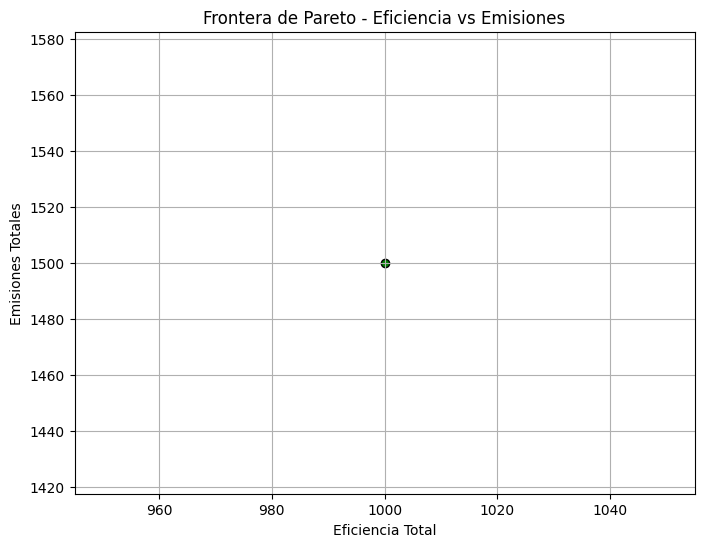

In [7]:
# Visualización de la Frontera de Pareto
x_vals = [ind.fitness.values[0] for ind in hof]
y_vals = [ind.fitness.values[1] for ind in hof]

plt.figure(figsize=(8,6))
plt.scatter(x_vals, y_vals, c='green', edgecolors='black')
plt.xlabel("Eficiencia Total")
plt.ylabel("Emisiones Totales")
plt.title("Frontera de Pareto - Eficiencia vs Emisiones")
plt.grid(True)
plt.show()

In [8]:
# Mostrar mejor trade-off
mejor_idx = np.argmax([x - 0.01*y for x, y in zip(x_vals, y_vals)])
print("Mejor solución (ponderación eficiencia - emisiones):", hof[mejor_idx])

Mejor solución (ponderación eficiencia - emisiones): [3, 3, 3, 3, 3, 3, 3, 3, 3, 3]
